In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

ds = load_dataset("fancyzhx/ag_news")
print(ds)

label_names = ds["train"].features["label"].names
print(label_names)  # ['World', 'Sports', 'Business', 'Sci/Tech']

train_df = ds["train"].to_pandas()
test_df = ds["test"].to_pandas()
train_df["label_name"] = train_df["label"].map(dict(enumerate(label_names)))
test_df["label_name"] = test_df["label"].map(dict(enumerate(label_names)))
train_df.head()

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})
['World', 'Sports', 'Business', 'Sci/Tech']


,text,label,label_name
0,Wall St. Bears Claw Back Into the Black (Reute...,2,Business
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2,Business
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2,Business
3,Iraq Halts Oil Exports from Main Southern Pipe...,2,Business
4,"Oil prices soar to all-time record, posing new...",2,Business


In [5]:
print("Train:", train_df.shape, "Test:", test_df.shape)
print(train_df.dtypes)
print("\nПропуски:\n", train_df.isna().sum())
print("\nПустые тексты:", (train_df["text"].str.strip() == "").sum())
print("Дубликаты текстов:", train_df["text"].duplicated().sum())

Train: (120000, 3) Test: (7600, 3)
text            str
label         int64
label_name      str
dtype: object

Пропуски:
 text          0
label         0
label_name    0
dtype: int64

Пустые тексты: 0
Дубликаты текстов: 0


label_name
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64
label_name
Business    25.0
Sci/Tech    25.0
Sports      25.0
World       25.0
Name: count, dtype: float64


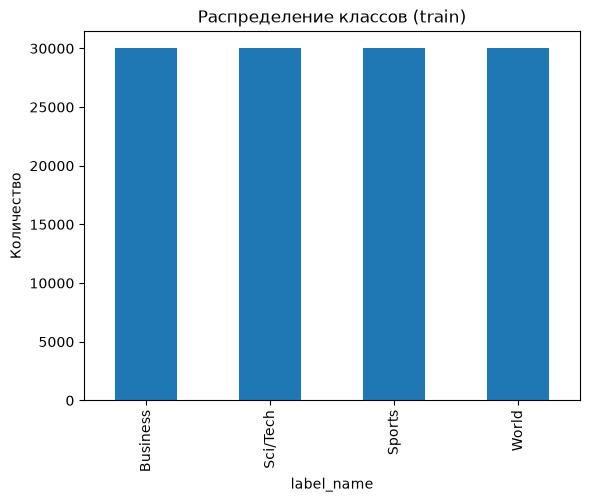

In [6]:
counts = train_df["label_name"].value_counts()
print(counts)
print((counts / len(train_df) * 100).round(1))

counts.plot(kind="bar", title="Распределение классов (train)")
plt.ylabel("Количество")
plt.show()

             n_chars        n_words
count  120000.000000  120000.000000
mean      236.477525      37.847450
std        66.509741      10.085245
min       100.000000       8.000000
25%       196.000000      32.000000
50%       232.000000      37.000000
75%       266.000000      43.000000
max      1012.000000     177.000000
              count       mean        std   min   25%   50%   75%    max
label_name                                                              
Business    30000.0  37.538233   8.121983   8.0  32.0  37.0  42.0  134.0
Sci/Tech    30000.0  37.191967  12.417603   8.0  30.0  36.0  42.0  177.0
Sports      30000.0  37.774733   8.870100   8.0  32.0  37.0  42.0  151.0
World       30000.0  38.884867  10.315517  11.0  33.0  39.0  44.0  145.0


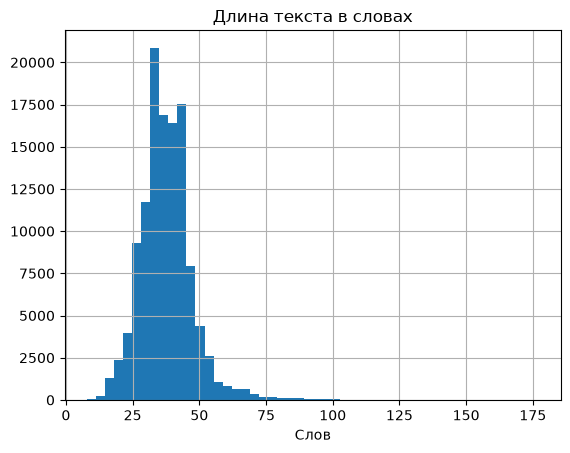

In [7]:
train_df["n_chars"] = train_df["text"].str.len()
train_df["n_words"] = train_df["text"].str.split().str.len()

print(train_df[["n_chars", "n_words"]].describe())
print(train_df.groupby("label_name")["n_words"].describe())

train_df["n_words"].hist(bins=50)
plt.title("Длина текста в словах")
plt.xlabel("Слов")
plt.show()

In [8]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

sample = train_df.sample(2000, random_state=42)
tok_lens = sample["text"].apply(lambda t: len(tokenizer(t)["input_ids"]))
print(tok_lens.describe())
print("95-й перцентиль:", tok_lens.quantile(0.95))

count    2000.000000
mean       53.211000
std        20.222511
min        21.000000
25%        43.000000
50%        50.000000
75%        59.000000
max       348.000000
Name: text, dtype: float64
95-й перцентиль: 82.0


In [9]:
for name in label_names:
    print(f"===== {name} =====")
    for t in train_df[train_df["label_name"] == name]["text"].sample(3, random_state=42):
        print("-", t[:300])
    print()

===== World =====
- Explosion Rocks Baghdad Neighborhood BAGHDAD, Iraq, August 24 -- A car bomb exploded near the gate of a US-funded Iraqi television network in Baghdad on Tuesday, killing at least two people and wounding two others, authorities and witnesses said.
- BBC reporters' log BBC correspondents record events in the Middle East and their thoughts as the funeral of the Palestinian leader Yasser Arafat takes place.
- Israel welcomes Rice nomination; Palestinians wary Israel on Tuesday warmly welcomed the naming of Condoleezza Rice as America #39;s top diplomat, but Palestinians were wary, saying the new Bush administration must put more energy into the quest for Middle East peace.

===== Sports =====
- Second Andre win in a row boosts US gold medal hopes Andre Dirrell, fighting with a tattoo of his grandfather #39;s face on his back, assured the United States of at least two boxing medals Wednesday by narrowly beating Cuba #39;s Yordani Despaigne to advance to the Olympic middl

In [10]:
import os
os.makedirs("data", exist_ok=True)
train_df[["text", "label", "label_name"]].to_csv("data/ag_news_train.csv", index=False)
test_df[["text", "label", "label_name"]].to_csv("data/ag_news_test.csv", index=False)

## Выводы по Дню 1

**Задача:** мультиклассовая классификация новостей AG News на 4 класса: World, Sports, Business, Sci/Tech.

**Размер и качество:**
- train — 120 000 текстов, test — 7 600;
- пропусков, пустых текстов и дубликатов нет;
- текст хранится одной колонкой: заголовок склеен с первым абзацем.

**Баланс классов:** идеальный, по 30 000 (25%) в каждом классе. Значит, accuracy подходит как основная метрика, macro-F1 берём дополнительно.

**Длина текстов:**
- в среднем ~38 слов (медиана 37), от 8 до 177; в символах от 100 до 1012;
- по классам длины почти одинаковые (медиана 36–39 слов), поэтому длина не помогает отличать классы;
- в токенах DistilBERT: медиана 50, 95-й перцентиль 82, максимум 348. Хватит `max_length=128`: обрежется меньше 5% текстов.

**Особенности и шум:**
- HTML-артефакты: `#39;` вместо апострофа, `quot;` вместо кавычек, `amp;` вместо &, а также `\$`. Их стоит почистить перед векторизацией;
- в начале текстов часто стоит источник или место: (Reuters), BAGHDAD, CALGARY и т. п.

**Ожидаемые сложности:**
- Business и Sci/Tech пересекаются: новости про IT-компании, чипы, сделки (пример: «Gartner optimistic about chip numbers» помечен как Sci/Tech, хотя по смыслу это бизнес);
- World и Business пересекаются на теме нефти и экономики (пример: «Iraq Halts Oil Exports» помечен как Business).